##1
# Application of Artificial Neural Network in Streamflow Forecasting

This project predicts daily streamflow using historical rainfall and streamflow observations.

Two neural-network models are implemented:

1. Feed-Forward Neural Network (FFNN)
2. Long Short-Term Memory Network (LSTM)

The target variable is daily streamflow. This is a regression problem because the output is a continuous numerical value.


##2
## Import Required Libraries

The following libraries are used for:

- Downloading data
- Data manipulation
- Numerical computation
- Visualization
- Feature scaling
- Building neural-network models
- Calculating evaluation metrics


In [1]:
import os
import io
import gzip
import hashlib
import requests
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, LSTM, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

warnings.filterwarnings("ignore")

np.random.seed(42)
tf.random.set_seed(42)

print("Libraries imported successfully.")
print("TensorFlow version:", tf.__version__)


Libraries imported successfully.
TensorFlow version: 2.21.0


##4
## Define the Study Configuration

The reference study focuses on the Leaf River near Collins, Mississippi.

The study period is 2003 to 2012.

The datasets used are:

- USGS daily mean streamflow from station 02472000
- NOAA daily precipitation from station USC00221852

The rainfall station is located in Collins, Mississippi. We will document this station choice as an implementation choice in the final report.


In [2]:
# Study configuration

START_DATE = "2003-01-01"
END_DATE = "2012-12-31"

USGS_SITE_NUMBER = "02472000"
NOAA_STATION_ID = "USC00221852"

RAW_DATA_DIR = "raw_data"
PROCESSED_DATA_DIR = "processed_data"
RESULTS_DIR = "results"

os.makedirs(RAW_DATA_DIR, exist_ok=True)
os.makedirs(PROCESSED_DATA_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)

print("Configuration completed.")
print("Study period:", START_DATE, "to", END_DATE)


Configuration completed.
Study period: 2003-01-01 to 2012-12-31


##6
## Download the Raw Streamflow Dataset

The USGS Water Services API provides daily streamflow observations.

The selected variable is daily mean discharge:

- Parameter code: 00060
- Statistic code: 00003
- Unit: cubic feet per second

The original response is saved before any processing is performed.


In [3]:
# Download raw USGS streamflow data

USGS_STREAMFLOW_URL = (
    "https://waterservices.usgs.gov/nwis/dv/"
    f"?format=rdb"
    f"&sites={USGS_SITE_NUMBER}"
    f"&startDT={START_DATE}"
    f"&endDT={END_DATE}"
    f"&statCd=00003"
    f"&parameterCd=00060"
 )

USGS_RAW_FILE = os.path.join(
    RAW_DATA_DIR,
    "usgs_leaf_river_streamflow_2003_2012.rdb"
)

response = requests.get(USGS_STREAMFLOW_URL, timeout=60)

if response.status_code == 200:
    with open(USGS_RAW_FILE, "wb") as file:
        file.write(response.content)

    print("USGS streamflow data downloaded successfully.")
    print("File:", USGS_RAW_FILE)
    print("Size:", os.path.getsize(USGS_RAW_FILE), "bytes")
else:
    raise Exception(
        f"USGS download failed with status code {response.status_code}"
    )


USGS streamflow data downloaded successfully.
File: raw_data/usgs_leaf_river_streamflow_2003_2012.rdb
Size: 116207 bytes


##8
## Download the Raw Rainfall Dataset

The NOAA Global Historical Climatology Network Daily dataset provides daily weather observations.

The precipitation variable is represented by the column `PRCP`.

NOAA stores precipitation in tenths of a millimeter. The unit conversion will be performed later during preprocessing.


In [4]:
# Download raw NOAA rainfall data

NOAA_RAINFALL_URL = (
    "https://www.ncei.noaa.gov/data/"
    "global-historical-climatology-network-daily/access/"
    f"{NOAA_STATION_ID}.csv"
 )

NOAA_RAW_FILE = os.path.join(
    RAW_DATA_DIR,
    "noaa_collins_rainfall_USC00221852.csv"
)

response = requests.get(NOAA_RAINFALL_URL, timeout=60)

if response.status_code == 200:
    with open(NOAA_RAW_FILE, "wb") as file:
        file.write(response.content)

    print("NOAA rainfall data downloaded successfully.")
    print("File:", NOAA_RAW_FILE)
    print("Size:", os.path.getsize(NOAA_RAW_FILE), "bytes")
else:
    raise Exception(
        f"NOAA download failed with status code {response.status_code}"
    )


NOAA rainfall data downloaded successfully.
File: raw_data/noaa_collins_rainfall_USC00221852.csv
Size: 6244583 bytes


## 10
## Load the Raw Streamflow Dataset

USGS RDB files contain metadata lines beginning with `#`.

The actual table contains:

- Agency code
- Site number
- Date
- Daily mean discharge
- Data-value qualification code

We load the file while ignoring metadata lines.


In [5]:
# Load the raw USGS RDB file

usgs_raw = pd.read_csv(
    USGS_RAW_FILE,
    sep="\t",
    comment="#",
    dtype=str
)

print("Raw USGS shape:", usgs_raw.shape)
print("\nUSGS columns:")
print(usgs_raw.columns.tolist())

display(usgs_raw.head())


Raw USGS shape: (3654, 5)

USGS columns:
['agency_cd', 'site_no', 'datetime', '294051_00060_00003', '294051_00060_00003_cd']


,agency_cd,site_no,datetime,294051_00060_00003,294051_00060_00003_cd
0,5s,15s,20d,14n,10s
1,USGS,02472000,2003-01-01,3210,A
2,USGS,02472000,2003-01-02,3620,A
3,USGS,02472000,2003-01-03,3450,A
4,USGS,02472000,2003-01-04,2330,A


##12
## Load the Raw Rainfall Dataset

The NOAA station file is a CSV file containing daily observations.

We first inspect the available columns before selecting precipitation.


In [6]:
# Load the raw NOAA rainfall file

rainfall_raw = pd.read_csv(NOAA_RAW_FILE)

print("Raw NOAA shape:", rainfall_raw.shape)
print("\nNOAA columns:")
print(rainfall_raw.columns.tolist())

display(rainfall_raw.head())


Raw NOAA shape: (35949, 40)

NOAA columns:
['STATION', 'DATE', 'LATITUDE', 'LONGITUDE', 'ELEVATION', 'NAME', 'PRCP', 'PRCP_ATTRIBUTES', 'SNOW', 'SNOW_ATTRIBUTES', 'SNWD', 'SNWD_ATTRIBUTES', 'TMAX', 'TMAX_ATTRIBUTES', 'TMIN', 'TMIN_ATTRIBUTES', 'DAPR', 'DAPR_ATTRIBUTES', 'MDPR', 'MDPR_ATTRIBUTES', 'TOBS', 'TOBS_ATTRIBUTES', 'WT01', 'WT01_ATTRIBUTES', 'WT03', 'WT03_ATTRIBUTES', 'WT04', 'WT04_ATTRIBUTES', 'WT05', 'WT05_ATTRIBUTES', 'WT06', 'WT06_ATTRIBUTES', 'WT07', 'WT07_ATTRIBUTES', 'WT11', 'WT11_ATTRIBUTES', 'WT16', 'WT16_ATTRIBUTES', 'WT18', 'WT18_ATTRIBUTES']


,STATION,DATE,LATITUDE,LONGITUDE,ELEVATION,NAME,PRCP,PRCP_ATTRIBUTES,SNOW,SNOW_ATTRIBUTES,...,WT06,WT06_ATTRIBUTES,WT07,WT07_ATTRIBUTES,WT11,WT11_ATTRIBUTES,WT16,WT16_ATTRIBUTES,WT18,WT18_ATTRIBUTES
0,USC00221852,1912-12-01,31.6419,-89.5572,88.4,"COLLINS, MS US",33.0,",,6,",0.0,",,6",...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,USC00221852,1912-12-02,31.6419,-89.5572,88.4,"COLLINS, MS US",0.0,"P,,6,",0.0,",,6",...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,USC00221852,1912-12-03,31.6419,-89.5572,88.4,"COLLINS, MS US",0.0,"P,,6,",0.0,",,6",...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,USC00221852,1912-12-04,31.6419,-89.5572,88.4,"COLLINS, MS US",1267.0,",,6,",0.0,",,6",...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,USC00221852,1912-12-05,31.6419,-89.5572,88.4,"COLLINS, MS US",455.0,",,6,",0.0,",,6",...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


##14
## Select and Rename the Required Variables

For streamflow, we use the daily mean discharge column.

For rainfall, we use the `PRCP` column.

The variables are renamed to:

- `date`
- `rainfall`
- `streamflow`

Renaming makes the dataset easier to use in the following steps.


In [7]:
# Identify the USGS date and discharge columns

print("USGS columns:")
print(usgs_raw.columns.tolist())

print("\nNOAA columns:")
print(rainfall_raw.columns.tolist())


USGS columns:
['agency_cd', 'site_no', 'datetime', '294051_00060_00003', '294051_00060_00003_cd']

NOAA columns:
['STATION', 'DATE', 'LATITUDE', 'LONGITUDE', 'ELEVATION', 'NAME', 'PRCP', 'PRCP_ATTRIBUTES', 'SNOW', 'SNOW_ATTRIBUTES', 'SNWD', 'SNWD_ATTRIBUTES', 'TMAX', 'TMAX_ATTRIBUTES', 'TMIN', 'TMIN_ATTRIBUTES', 'DAPR', 'DAPR_ATTRIBUTES', 'MDPR', 'MDPR_ATTRIBUTES', 'TOBS', 'TOBS_ATTRIBUTES', 'WT01', 'WT01_ATTRIBUTES', 'WT03', 'WT03_ATTRIBUTES', 'WT04', 'WT04_ATTRIBUTES', 'WT05', 'WT05_ATTRIBUTES', 'WT06', 'WT06_ATTRIBUTES', 'WT07', 'WT07_ATTRIBUTES', 'WT11', 'WT11_ATTRIBUTES', 'WT16', 'WT16_ATTRIBUTES', 'WT18', 'WT18_ATTRIBUTES']


In [8]:
# Prepare the USGS streamflow table

# Reload the USGS file while ignoring metadata lines
usgs_raw = pd.read_csv(
    USGS_RAW_FILE,
    sep="\t",
    comment="#",
    dtype=str,
    skip_blank_lines=True
)

# Remove leading and trailing spaces from column names
usgs_raw.columns = usgs_raw.columns.astype(str).str.strip()

print("USGS columns detected:")
print(usgs_raw.columns.tolist())

# Remove the USGS format-description row.
# This row usually contains values such as:
# 5s, 15s, 20d, 6s, 14n, 10s
if "datetime" in usgs_raw.columns:
    usgs_raw = usgs_raw[
        usgs_raw["datetime"].astype(str).str.match(
            r"^\d{4}-\d{2}-\d{2}",
            na=False
        )
    ].copy()
else:
    raise KeyError(
        "The USGS datetime column was not found. "
        "Check the printed column names above."
    )

# Locate the discharge column.
# The USGS discharge parameter code is 00060.
possible_flow_columns = [
    column for column in usgs_raw.columns
    if "00060" in str(column)
    and "cd" not in str(column).lower()
]

print("\nPossible discharge columns:")
print(possible_flow_columns)

if len(possible_flow_columns) == 0:
    raise KeyError(
        "USGS discharge column was not found. "
        "Check the printed USGS columns above."
    )

usgs_flow_column = possible_flow_columns[0]

# Select and rename the required columns
streamflow = usgs_raw[
    ["datetime", usgs_flow_column]
].copy()

streamflow.columns = ["date", "streamflow"]

# Convert data types
streamflow["date"] = pd.to_datetime(
    streamflow["date"],
    errors="coerce"
)

streamflow["streamflow"] = pd.to_numeric(
    streamflow["streamflow"],
    errors="coerce"
)

# Remove invalid rows
streamflow = streamflow.dropna(
    subset=["date", "streamflow"]
).reset_index(drop=True)

print("\nSelected USGS discharge column:", usgs_flow_column)
print("Prepared streamflow shape:", streamflow.shape)
print("\nStreamflow data types:")
print(streamflow.dtypes)

display(streamflow.head())


USGS columns detected:
['agency_cd', 'site_no', 'datetime', '294051_00060_00003', '294051_00060_00003_cd']

Possible discharge columns:
['294051_00060_00003']

Selected USGS discharge column: 294051_00060_00003
Prepared streamflow shape: (3653, 2)

Streamflow data types:
date          datetime64[ns]
streamflow           float64
dtype: object


,date,streamflow
0,2003-01-01,3210.0
1,2003-01-02,3620.0
2,2003-01-03,3450.0
3,2003-01-04,2330.0
4,2003-01-05,1180.0


In [9]:
# Prepare the NOAA rainfall table

rainfall = rainfall_raw.copy()

required_columns = ["DATE", "PRCP"]

for column in required_columns:
    if column not in rainfall.columns:
        raise KeyError(
            f"Required NOAA column '{column}' was not found."
        )

rainfall = rainfall[["DATE", "PRCP"]].copy()
rainfall.columns = ["date", "rainfall"]

rainfall["date"] = pd.to_datetime(
    rainfall["date"],
    errors="coerce"
)

rainfall["rainfall"] = pd.to_numeric(
    rainfall["rainfall"],
    errors="coerce"
)

rainfall = rainfall.dropna(subset=["date"])

print("Prepared rainfall table:")
display(rainfall.head())
print(rainfall.dtypes)


Prepared rainfall table:


,date,rainfall
0,1912-12-01,33.0
1,1912-12-02,0.0
2,1912-12-03,0.0
3,1912-12-04,1267.0
4,1912-12-05,455.0


date        datetime64[ns]
rainfall           float64
dtype: object


##18
## Restrict the Observations to the Study Period

The downloaded station files may contain observations before or after the selected study period.

We select only dates from 1 January 2003 through 31 December 2012.

This is date selection, not model-based preprocessing.


In [10]:
# Restrict both datasets to the study period

start_date = pd.to_datetime(START_DATE)
end_date = pd.to_datetime(END_DATE)

streamflow = streamflow[
    (streamflow["date"] >= start_date)
    & (streamflow["date"] <= end_date)
].copy()

rainfall = rainfall[
    (rainfall["date"] >= start_date)
    & (rainfall["date"] <= end_date)
].copy()

print("Streamflow date range:")
print(streamflow["date"].min(), "to", streamflow["date"].max())

print("\nRainfall date range:")
print(rainfall["date"].min(), "to", rainfall["date"].max())


Streamflow date range:
2003-01-01 00:00:00 to 2012-12-31 00:00:00

Rainfall date range:
2003-01-01 00:00:00 to 2012-12-31 00:00:00


##20
## Convert Rainfall Units

NOAA GHCN-Daily precipitation values are stored in tenths of a millimeter.

For example:

- Raw value `10` means `1.0 mm`
- Raw value `25` means `2.5 mm`

We convert precipitation to millimeters by dividing the raw values by 10.


In [11]:
# Convert NOAA precipitation from tenths of millimeters to millimeters

rainfall["rainfall_mm"] = rainfall["rainfall"] / 10.0

rainfall = rainfall[["date", "rainfall_mm"]].copy()
rainfall.columns = ["date", "rainfall"]

print("Rainfall values after unit conversion:")
display(rainfall.head())


Rainfall values after unit conversion:


,date,rainfall
31090,2003-01-01,20.6
31091,2003-01-02,0.5
31092,2003-01-03,0.8
31093,2003-01-04,0.0
31094,2003-01-05,0.0


##22
## Inspect the Raw Variables

Before merging the datasets, we inspect:

- Number of records
- Date ranges
- Missing values
- Minimum values
- Maximum values
- Basic statistical summaries

This helps identify problems before model preparation.


In [12]:
# Inspect streamflow and rainfall tables

print("STREAMFLOW SUMMARY")
print("------------------")
print("Records:", len(streamflow))
print("Date range:", streamflow["date"].min(), "to", streamflow["date"].max())
print("Missing values:")
print(streamflow.isna().sum())
display(streamflow.describe())

print("\nRAINFALL SUMMARY")
print("----------------")
print("Records:", len(rainfall))
print("Date range:", rainfall["date"].min(), "to", rainfall["date"].max())
print("Missing values:")
print(rainfall.isna().sum())
display(rainfall.describe())


STREAMFLOW SUMMARY
------------------
Records: 3653
Date range: 2003-01-01 00:00:00 to 2012-12-31 00:00:00
Missing values:
date          0
streamflow    0
dtype: int64


,date,streamflow
count,3653,3653.000000
mean,2008-01-01 00:00:00,858.024583
min,2003-01-01 00:00:00,53.300000
25%,2005-07-02 00:00:00,135.000000
50%,2008-01-01 00:00:00,280.000000
75%,2010-07-02 00:00:00,689.000000
max,2012-12-31 00:00:00,29700.000000
std,NaN,1859.100855



RAINFALL SUMMARY
----------------
Records: 3652
Date range: 2003-01-01 00:00:00 to 2012-12-31 00:00:00
Missing values:
date         0
rainfall    45
dtype: int64


,date,rainfall
count,3652,3607.000000
mean,2007-12-31 14:50:44.030668032,3.858913
min,2003-01-01 00:00:00,0.000000
25%,2005-07-01 18:00:00,0.000000
50%,2007-12-31 12:00:00,0.000000
75%,2010-07-01 06:00:00,0.000000
max,2012-12-31 00:00:00,176.800000
std,NaN,12.480957


##24
## Merge Rainfall and Streamflow by Date

Rainfall and streamflow must correspond to the same date.

An inner merge keeps only dates available in both datasets.

After merging, each row represents one day with:

- Date
- Rainfall
- Streamflow


In [13]:
# Merge rainfall and streamflow using the date column

data = pd.merge(
    rainfall,
    streamflow,
    on="date",
    how="inner"
)

data = data.sort_values("date").reset_index(drop=True)

print("Merged dataset shape:", data.shape)
display(data.head())
display(data.tail())


Merged dataset shape: (3652, 3)


,date,rainfall,streamflow
0,2003-01-01,20.6,3210.0
1,2003-01-02,0.5,3620.0
2,2003-01-03,0.8,3450.0
3,2003-01-04,0.0,2330.0
4,2003-01-05,0.0,1180.0


,date,rainfall,streamflow
3647,2012-12-27,0.0,3920.0
3648,2012-12-28,0.0,6040.0
3649,2012-12-29,68.6,9110.0
3650,2012-12-30,0.0,6890.0
3651,2012-12-31,0.0,6450.0


##26
## Clean Invalid Values

Rainfall and streamflow cannot be negative.

We replace negative values with missing values and then remove incomplete rows.

This step is performed only after inspecting the raw datasets.


In [14]:
# Remove invalid negative values

data.loc[data["rainfall"] < 0, "rainfall"] = np.nan
data.loc[data["streamflow"] < 0, "streamflow"] = np.nan

print("Missing values before removing incomplete rows:")
print(data.isna().sum())

data = data.dropna(subset=["rainfall", "streamflow"]).copy()

data = data.sort_values("date").reset_index(drop=True)

print("\nDataset shape after cleaning:", data.shape)
print("Remaining missing values:")
print(data.isna().sum())


Missing values before removing incomplete rows:
date           0
rainfall      45
streamflow     0
dtype: int64

Dataset shape after cleaning: (3607, 3)
Remaining missing values:
date          0
rainfall      0
streamflow    0
dtype: int64


##28
## Verify the Prepared Dataset

The prepared dataset should contain one row per date with two numerical variables:

- `rainfall`
- `streamflow`

The dates must be sorted chronologically because this is a time-series problem.


In [15]:
# Verify the prepared dataset

print("Dataset information:")
data.info()

print("\nDate range:")
print(data["date"].min(), "to", data["date"].max())

print("\nNumber of duplicate dates:")
print(data["date"].duplicated().sum())

print("\nNumber of missing values:")
print(data.isna().sum())

print("\nFirst five rows:")
display(data.head())


Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3607 entries, 0 to 3606
Data columns (total 3 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   date        3607 non-null   datetime64[ns]
 1   rainfall    3607 non-null   float64       
 2   streamflow  3607 non-null   float64       
dtypes: datetime64[ns](1), float64(2)
memory usage: 84.7 KB

Date range:
2003-01-01 00:00:00 to 2012-12-31 00:00:00

Number of duplicate dates:
0

Number of missing values:
date          0
rainfall      0
streamflow    0
dtype: int64

First five rows:


,date,rainfall,streamflow
0,2003-01-01,20.6,3210.0
1,2003-01-02,0.5,3620.0
2,2003-01-03,0.8,3450.0
3,2003-01-04,0.0,2330.0
4,2003-01-05,0.0,1180.0


##30
## Visualize Rainfall and Streamflow

These plots show the time-series behavior of rainfall and streamflow.

Rainfall may contain many zero values with occasional large events.

Streamflow generally changes more smoothly but may contain high-flow peaks after rainfall events.

**bold text**

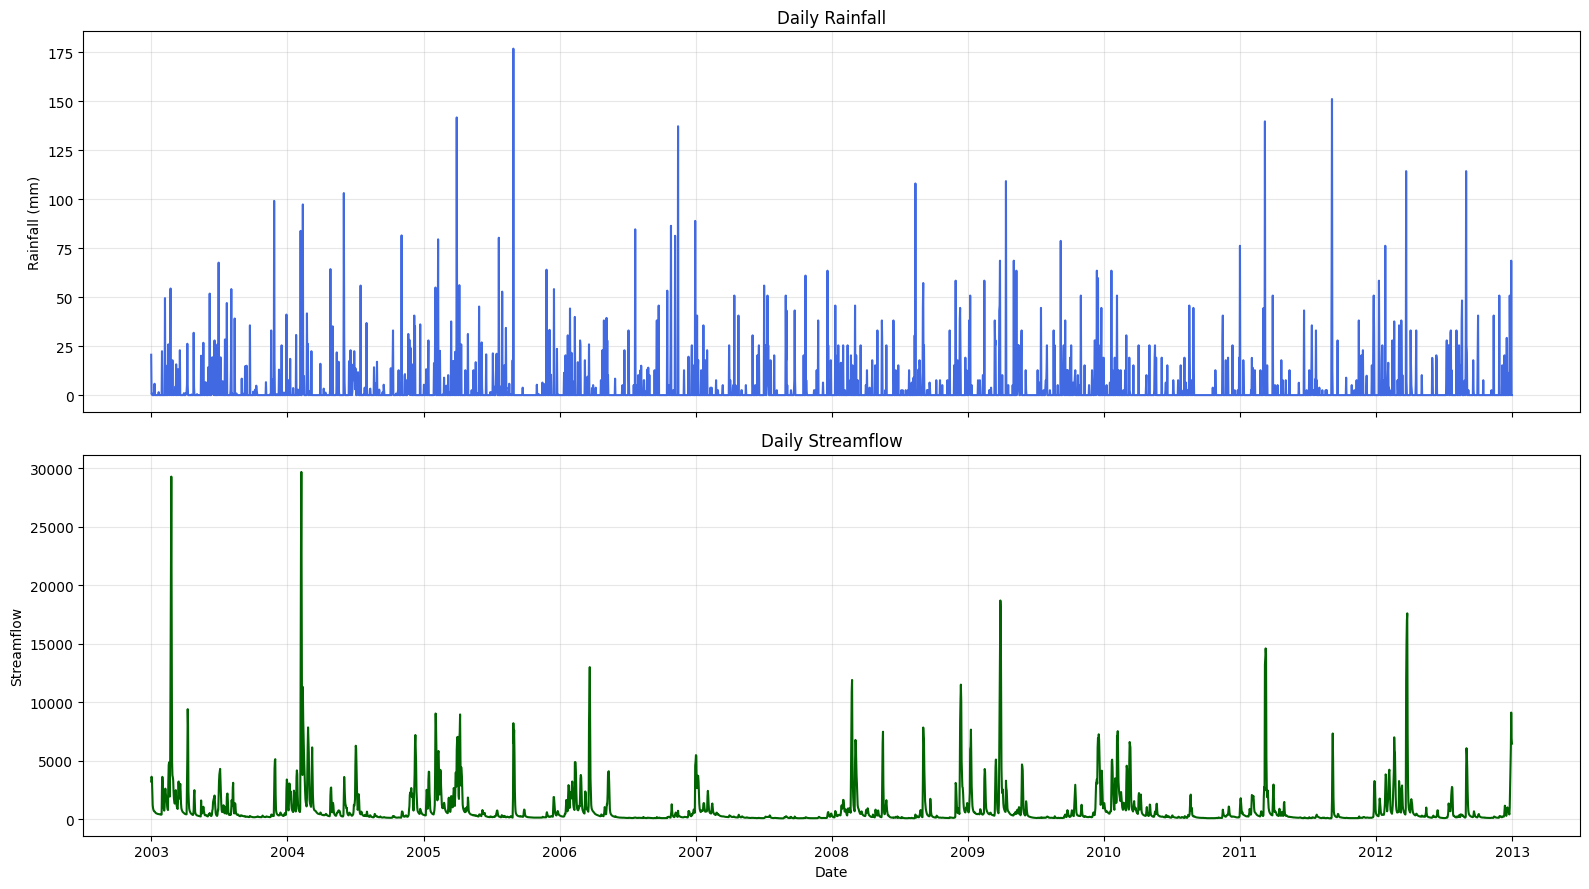

In [16]:
# Plot rainfall and streamflow

fig, axes = plt.subplots(2, 1, figsize=(16, 9), sharex=True)

axes[0].plot(data["date"], data["rainfall"], color="royalblue")
axes[0].set_title("Daily Rainfall")
axes[0].set_ylabel("Rainfall (mm)")
axes[0].grid(True, alpha=0.3)

axes[1].plot(data["date"], data["streamflow"], color="darkgreen")
axes[1].set_title("Daily Streamflow")
axes[1].set_ylabel("Streamflow")
axes[1].set_xlabel("Date")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


# 32 — Create the Lag Features

The model uses seven historical input features:

- Three rainfall lags:
  - Rainfall lag 1
  - Rainfall lag 2
  - Rainfall lag 3

- Four streamflow lags:
  - Streamflow lag 1
  - Streamflow lag 2
  - Streamflow lag 3
  - Streamflow lag 4

These seven lagged values are used to predict the current-day streamflow.


In [17]:
# Define the rainfall and streamflow lag lengths

RAINFALL_LAG_DAYS = 3
STREAMFLOW_LAG_DAYS = 4

lagged_data = data.copy()

# Create rainfall lag features

for lag in range(1, RAINFALL_LAG_DAYS + 1):
    lagged_data[f"rainfall_lag_{lag}"] = (
        lagged_data["rainfall"].shift(lag)
    )

# Create streamflow lag features

for lag in range(1, STREAMFLOW_LAG_DAYS + 1):
    lagged_data[f"streamflow_lag_{lag}"] = (
        lagged_data["streamflow"].shift(lag)
    )

# Remove rows with incomplete lag information

lagged_data = (
    lagged_data
    .dropna()
    .reset_index(drop=True)
)

print("Rainfall lag days:", RAINFALL_LAG_DAYS)
print("Streamflow lag days:", STREAMFLOW_LAG_DAYS)
print("Total input features:", RAINFALL_LAG_DAYS + STREAMFLOW_LAG_DAYS)
print("Lagged dataset shape:", lagged_data.shape)

display(lagged_data.head())


Rainfall lag days: 3
Streamflow lag days: 4
Total input features: 7
Lagged dataset shape: (3603, 10)


,date,rainfall,streamflow,rainfall_lag_1,rainfall_lag_2,rainfall_lag_3,streamflow_lag_1,streamflow_lag_2,streamflow_lag_3,streamflow_lag_4
0,2003-01-05,0.0,1180.0,0.0,0.8,0.5,2330.0,3450.0,3620.0,3210.0
1,2003-01-06,0.0,932.0,0.0,0.0,0.8,1180.0,2330.0,3450.0,3620.0
2,2003-01-07,0.0,791.0,0.0,0.0,0.0,932.0,1180.0,2330.0,3450.0
3,2003-01-08,0.0,705.0,0.0,0.0,0.0,791.0,932.0,1180.0,2330.0
4,2003-01-09,0.0,654.0,0.0,0.0,0.0,705.0,791.0,932.0,1180.0


#  34 — Define the Model Features and Target

The model uses seven input features:

1. Rainfall lag 1
2. Rainfall lag 2
3. Rainfall lag 3
4. Streamflow lag 1
5. Streamflow lag 2
6. Streamflow lag 3
7. Streamflow lag 4

The target is the current-day streamflow.


In [18]:
# Define the seven model input features

feature_columns = [
    f"rainfall_lag_{lag}"
    for lag in range(1, RAINFALL_LAG_DAYS + 1)
]

feature_columns += [
    f"streamflow_lag_{lag}"
    for lag in range(1, STREAMFLOW_LAG_DAYS + 1)
]

target_column = "streamflow"

X = lagged_data[feature_columns].copy()
y = lagged_data[target_column].copy()

print("Feature columns:")
for number, column in enumerate(feature_columns, start=1):
    print(f"{number}. {column}")

print("\nNumber of input features:", len(feature_columns))
print("Feature shape:", X.shape)
print("Target shape:", y.shape)


Feature columns:
1. rainfall_lag_1
2. rainfall_lag_2
3. rainfall_lag_3
4. streamflow_lag_1
5. streamflow_lag_2
6. streamflow_lag_3
7. streamflow_lag_4

Number of input features: 7
Feature shape: (3603, 7)
Target shape: (3603,)


#36
## Split the Data Chronologically
## train-valid split

Time-series data must not be randomly shuffled before splitting.

We use:

- Training period: 2003–2007
- Validation period: 2008–2012

The model learns from earlier dates and is evaluated on later dates.


In [19]:
# Chronological training-validation split

TRAIN_END_DATE = "2007-12-31"

train_mask = lagged_data["date"] <= pd.to_datetime(TRAIN_END_DATE)
validation_mask = lagged_data["date"] > pd.to_datetime(TRAIN_END_DATE)

X_train = X.loc[train_mask].copy()
X_validation = X.loc[validation_mask].copy()

y_train = y.loc[train_mask].copy()
y_validation = y.loc[validation_mask].copy()

dates_train = lagged_data.loc[train_mask, "date"].copy()
dates_validation = lagged_data.loc[validation_mask, "date"].copy()

print("Training samples:", len(X_train))
print("Validation samples:", len(X_validation))

print("\nTraining dates:")
print(dates_train.min(), "to", dates_train.max())

print("\nValidation dates:")
print(dates_validation.min(), "to", dates_validation.max())


Training samples: 1807
Validation samples: 1796

Training dates:
2003-01-05 00:00:00 to 2007-12-31 00:00:00

Validation dates:
2008-01-01 00:00:00 to 2012-12-31 00:00:00


#  38 — Scale the Features and Target

Min-Max scaling transforms the input features and target approximately into the range 0 to 1.

The scalers are fitted only on the training data.

The validation data is transformed using the scalers fitted on the training data.


In [20]:
# Scale the FFNN features and target using training data only

feature_scaler = MinMaxScaler()
target_scaler = MinMaxScaler()

X_train_scaled = feature_scaler.fit_transform(X_train)
X_validation_scaled = feature_scaler.transform(X_validation)

y_train_scaled = target_scaler.fit_transform(
    y_train.to_numpy().reshape(-1, 1)
)

y_validation_scaled = target_scaler.transform(
    y_validation.to_numpy().reshape(-1, 1)
)

print("Training feature shape:", X_train_scaled.shape)
print("Validation feature shape:", X_validation_scaled.shape)
print("Training target shape:", y_train_scaled.shape)
print("Validation target shape:", y_validation_scaled.shape)


Training feature shape: (1807, 7)
Validation feature shape: (1796, 7)
Training target shape: (1807, 1)
Validation target shape: (1796, 1)


# 40 — Build the  Feed-Forward Neural Network

The Feed-Forward Neural Network uses seven input features:

- Three rainfall lags
- Four streamflow lags

The network contains one hidden layer with:

- 12 neurons
- Sigmoid activation

The output layer contains one linear neuron to predict the current-day streamflow.

RMSE is used as the loss function and the only model metric.


In [21]:
# Build the tuned Feed-Forward Neural Network

ffnn_model = Sequential([
    Dense(
        12,
        activation="sigmoid",
        input_shape=(X_train_scaled.shape[1],)
    ),
    Dense(
        1,
        activation="linear"
    )
])


# Define RMSE as the loss function

def rmse_loss(y_true, y_pred):
    error = y_true - y_pred
    squared_error = tf.square(error)
    mean_squared_error_value = tf.reduce_mean(
        squared_error
    )

    return tf.sqrt(
        mean_squared_error_value
        + tf.keras.backend.epsilon()
    )


# Compile the FFNN using RMSE only

ffnn_model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss=rmse_loss,
    metrics=[
        tf.keras.metrics.RootMeanSquaredError(
            name="rmse"
        )
    ]
)

ffnn_model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 12)             │            96 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            13 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109 (436.00 B)

 Trainable params: 109 (436.00 B)

 Non-trainable params: 0 (0.00 B)

#  42 — Train the Tuned Feed-Forward Neural Network

The tuned FFNN is trained using:

- RMSE as the loss function
- RMSE as the only metric
- Adam optimizer
- Learning rate of 0.001
- Exactly 200 epochs
- Batch size of 32
- No early stopping

The data is not shuffled because it is time-series data.


In [22]:
# Train the tuned FFNN for exactly 200 epochs

history_ffnn = ffnn_model.fit(
    X_train_scaled,
    y_train_scaled,
    validation_data=(
        X_validation_scaled,
        y_validation_scaled
    ),
    epochs=200,
    batch_size=32,
    shuffle=False,
    verbose=1
)


Epoch 1/200
57/57 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0433 - rmse: 0.0642 - val_loss: 0.0318 - val_rmse: 0.0512
Epoch 2/200
57/57 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0319 - rmse: 0.0551 - val_loss: 0.0314 - val_rmse: 0.0489
Epoch 3/200
57/57 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0301 - rmse: 0.0526 - val_loss: 0.0294 - val_rmse: 0.0459
Epoch 4/200
57/57 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0287 - rmse: 0.0502 - val_loss: 0.0282 - val_rmse: 0.0439
Epoch 5/200
57/57 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0277 - rmse: 0.0486 - val_loss: 0.0272 - val_rmse: 0.0422
Epoch 6/200
57/57 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0270 - rmse: 0.0473 - val_loss: 0.0265 - val_rmse: 0.0410
Epoch 7/200
57/57 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0264 - rmse: 0.0463 - val_loss: 0.0259 - val_rmse: 0.0401
Epoch 8/200
57/57 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0259 - rmse: 0.0454 - val_loss: 0.0254 - val_rmse: 0.0393
Epoch 9/200
57/57 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/st

#  44 — Plot FFNN Training and Validation RMSE

This plot shows the training RMSE and validation RMSE for all 200 epochs.


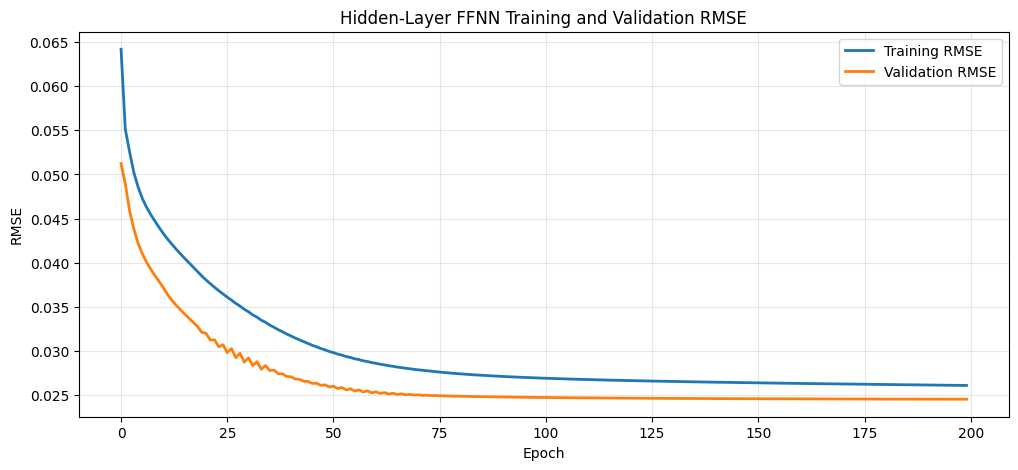

FFNN average RMSE table:


,Metric,RMSE
0,Average Training RMSE,0.029739
1,Average Validation RMSE,0.026694


In [23]:
# Plot FFNN training and validation RMSE

plt.figure(figsize=(12, 5))

plt.plot(
    history_ffnn.history["rmse"],
    label="Training RMSE",
    linewidth=2
)

plt.plot(
    history_ffnn.history["val_rmse"],
    label="Validation RMSE",
    linewidth=2
)

plt.title(
    "Hidden-Layer FFNN Training and Validation RMSE"
)
plt.xlabel("Epoch")
plt.ylabel("RMSE")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# Calculate average FFNN training and validation RMSE

average_training_rmse = np.mean(
    history_ffnn.history["rmse"]
)

average_validation_rmse = np.mean(
    history_ffnn.history["val_rmse"]
)

ffnn_average_rmse_table = pd.DataFrame({
    "Metric": [
        "Average Training RMSE",
        "Average Validation RMSE"
    ],
    "RMSE": [
        average_training_rmse,
        average_validation_rmse
    ]
})

ffnn_average_rmse_table["RMSE"] = (
    ffnn_average_rmse_table["RMSE"].round(6)
)

print("FFNN average RMSE table:")
display(ffnn_average_rmse_table)


#  46 — Generate Feed-Forward Neural Network Predictions

The trained FFNN generates predictions for the validation dataset.

The predictions are converted from the scaled range back to the original streamflow scale.


In [24]:
# Generate FFNN predictions for the validation dataset

ffnn_predictions_scaled = ffnn_model.predict(
    X_validation_scaled,
    verbose=0
)

# Convert predictions back to the original streamflow scale
ffnn_predictions = target_scaler.inverse_transform(
    ffnn_predictions_scaled
).flatten()

# Convert the validation target to a one-dimensional NumPy array
actual_streamflow = y_validation.to_numpy().flatten()

print("FFNN predictions generated successfully.")
print("Number of FFNN predictions:", len(ffnn_predictions))
print("Number of actual streamflow values:", len(actual_streamflow))


FFNN predictions generated successfully.
Number of FFNN predictions: 1796
Number of actual streamflow values: 1796


#  48 — Prepare the Data for the LSTM

The LSTM uses a shorter sequence of three previous days.

Each time step contains:

- Rainfall
- Streamflow



In [25]:
# Prepare the rainfall and streamflow data for the LSTM

lstm_base = data[
    ["date", "rainfall", "streamflow"]
].copy()

lstm_base = lstm_base.sort_values(
    "date"
).reset_index(drop=True)

LSTM_SEQUENCE_LENGTH = 3

lstm_feature_scaler = MinMaxScaler()
lstm_target_scaler = MinMaxScaler()

lstm_train_mask = (
    lstm_base["date"] <= pd.to_datetime(TRAIN_END_DATE)
)

# Fit scalers only on the training period

lstm_feature_scaler.fit(
    lstm_base.loc[
        lstm_train_mask,
        ["rainfall", "streamflow"]
    ]
)

lstm_target_scaler.fit(
    lstm_base.loc[
        lstm_train_mask,
        ["streamflow"]
    ]
)

# Transform features and target

lstm_scaled_features = lstm_feature_scaler.transform(
    lstm_base[["rainfall", "streamflow"]]
)

lstm_scaled_target = lstm_target_scaler.transform(
    lstm_base[["streamflow"]]
).flatten()

print("LSTM sequence length:", LSTM_SEQUENCE_LENGTH)
print(
    "Scaled LSTM feature shape:",
    lstm_scaled_features.shape
)
print(
    "Scaled LSTM target shape:",
    lstm_scaled_target.shape
)


LSTM sequence length: 3
Scaled LSTM feature shape: (3607, 2)
Scaled LSTM target shape: (3607,)


#  50 — Create LSTM Time Sequences

Each LSTM input sequence contains three previous days.

For example:

```text
Days 1–3  → predict Day 4
Days 2–4  → predict Day 5
Days 3–5  → predict Day 6


In [26]:

## Code Cell
# Create three-day rolling sequences for the LSTM

X_lstm = []
y_lstm = []
lstm_dates = []

for index in range(
    LSTM_SEQUENCE_LENGTH,
    len(lstm_scaled_features)
):
    sequence = lstm_scaled_features[
        index - LSTM_SEQUENCE_LENGTH:index
    ]

    target = lstm_scaled_target[index]

    X_lstm.append(sequence)
    y_lstm.append(target)
    lstm_dates.append(
        lstm_base.loc[index, "date"]
    )

X_lstm = np.array(X_lstm)
y_lstm = np.array(y_lstm)
lstm_dates = pd.to_datetime(lstm_dates)

print("LSTM input shape:", X_lstm.shape)
print("LSTM target shape:", y_lstm.shape)


LSTM input shape: (3604, 3, 2)
LSTM target shape: (3604,)


#  52 — Split the LSTM Data into Training and Validation Sets

The LSTM sequences are split chronologically.

- Training data contains target dates through 31 December 2007.
- Validation data contains target dates after 31 December 2007.

The data is not randomly shuffled.


In [27]:
# Split the LSTM sequences chronologically

lstm_train_mask = (
    lstm_dates <= pd.to_datetime(TRAIN_END_DATE)
)

lstm_validation_mask = (
    lstm_dates > pd.to_datetime(TRAIN_END_DATE)
)

X_lstm_train = X_lstm[lstm_train_mask]
X_lstm_validation = X_lstm[lstm_validation_mask]

y_lstm_train = y_lstm[lstm_train_mask]
y_lstm_validation = y_lstm[lstm_validation_mask]

dates_lstm_validation = lstm_dates[
    lstm_validation_mask
]

print("LSTM training shape:", X_lstm_train.shape)
print("LSTM validation shape:", X_lstm_validation.shape)
print(
    "LSTM training target shape:",
    y_lstm_train.shape
)
print(
    "LSTM validation target shape:",
    y_lstm_validation.shape
)


LSTM training shape: (1808, 3, 2)
LSTM validation shape: (1796, 3, 2)
LSTM training target shape: (1808,)
LSTM validation target shape: (1796,)


#54 — Build the Single-Hidden-Layer LSTM
The LSTM model contains a single hidden layer:
1. Single LSTM layer with 32 units

The LSTM layer processes the 3-day time sequences and outputs directly to the final Dense layer (`return_sequences=False`).
The final dense layer contains one neuron because the model predicts one continuous streamflow value.
The LSTM uses a learning rate of 0.002.
RMSE is used as the loss function and primary evaluation metric.

In [28]:
lstm_model = Sequential([
    LSTM(
        32,
        activation="tanh",
        return_sequences=False,
        input_shape=(X_lstm_train.shape[1], X_lstm_train.shape[2])
    ),
    Dense(1, activation="linear")
])

lstm_model.summary()

lstm_model.compile(
    optimizer=Adam(learning_rate=0.002),
    loss=rmse_loss,
    metrics=[tf.keras.metrics.RootMeanSquaredError(name="rmse")]
)

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 32)             │         4,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,513 (17.63 KB)

 Trainable params: 4,513 (17.63 KB)

 Non-trainable params: 0 (0.00 B)

## 56 — Train and Validate the Single-Hidden-Layer LSTM
The single-hidden-layer LSTM is trained using:
- RMSE as the loss function
- Adam optimizer
- Learning rate of 0.002
- Exactly 200 epochs
- Batch size of 32
- No early stopping

The sequence order is preserved by setting `shuffle=False`.

In [29]:
history_lstm = lstm_model.fit(
    X_lstm_train,
    y_lstm_train,
    validation_data=(X_lstm_validation, y_lstm_validation),
    epochs=200,
    batch_size=32,
    shuffle=False,
    verbose=1
)

Epoch 1/200
57/57 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - loss: 0.0375 - rmse: 0.0648 - val_loss: 0.0314 - val_rmse: 0.0482
Epoch 2/200
57/57 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0296 - rmse: 0.0512 - val_loss: 0.0271 - val_rmse: 0.0419
Epoch 3/200
57/57 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0271 - rmse: 0.0477 - val_loss: 0.0250 - val_rmse: 0.0396
Epoch 4/200
57/57 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0256 - rmse: 0.0454 - val_loss: 0.0235 - val_rmse: 0.0373
Epoch 5/200
57/57 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0242 - rmse: 0.0429 - val_loss: 0.0224 - val_rmse: 0.0349
Epoch 6/200
57/57 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0226 - rmse: 0.0400 - val_loss: 0.0212 - val_rmse: 0.0322
Epoch 7/200
57/57 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0208 - rmse: 0.0367 - val_loss: 0.0194 - val_rmse: 0.0295
Epoch 8/200
57/57 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0189 - rmse: 0.0332 - val_loss: 0.0179 - val_rmse: 0.0269
Epoch 9/200
57/57 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/

#  58 — Plot LSTM Training and Validation RMSE

This plot shows the training RMSE and validation RMSE for all 200 epochs.


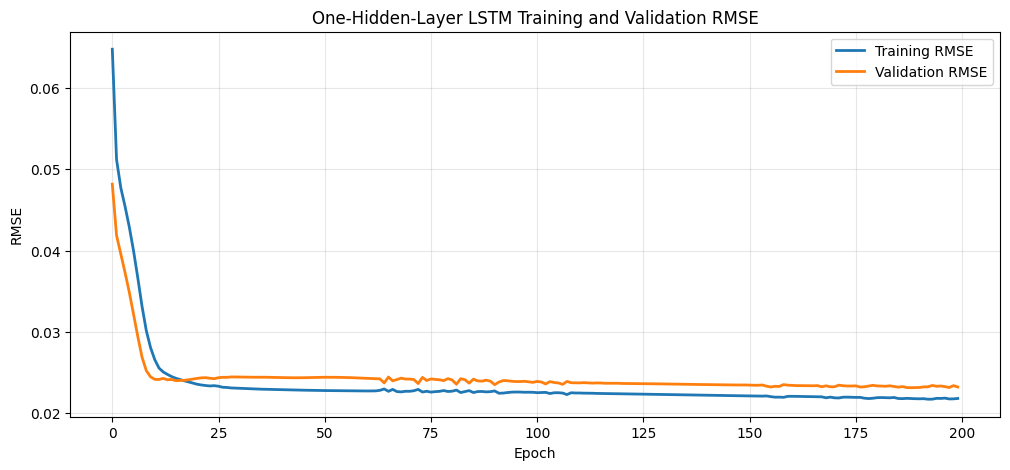

LSTM average RMSE table:


,Metric,RMSE
0,Average Training RMSE,0.023542
1,Average Validation RMSE,0.024344


In [30]:
# Plot LSTM training and validation RMSE

plt.figure(figsize=(12, 5))

plt.plot(
    history_lstm.history["rmse"],
    label="Training RMSE",
    linewidth=2
)

plt.plot(
    history_lstm.history["val_rmse"],
    label="Validation RMSE",
    linewidth=2
)

plt.title(
    "One-Hidden-Layer LSTM Training and Validation RMSE"
)
plt.xlabel("Epoch")
plt.ylabel("RMSE")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# Calculate average LSTM training and validation RMSE

average_training_rmse_lstm = np.mean(
    history_lstm.history["rmse"]
)

average_validation_rmse_lstm = np.mean(
    history_lstm.history["val_rmse"]
)

lstm_average_rmse_table = pd.DataFrame({
    "Metric": [
        "Average Training RMSE",
        "Average Validation RMSE"
    ],
    "RMSE": [
        average_training_rmse_lstm,
        average_validation_rmse_lstm
    ]
})

lstm_average_rmse_table["RMSE"] = (
    lstm_average_rmse_table["RMSE"].round(6)
)

print("LSTM average RMSE table:")
display(lstm_average_rmse_table)


#  60 — Generate LSTM Predictions

The LSTM predictions are converted from the scaled range back to the original streamflow scale.


In [31]:
# Generate LSTM predictions

lstm_predictions_scaled = lstm_model.predict(
    X_lstm_validation,
    verbose=0
)

lstm_predictions = (
    lstm_target_scaler.inverse_transform(
        lstm_predictions_scaled
    )
    .flatten()
)

actual_lstm_streamflow = (
    lstm_target_scaler.inverse_transform(
        y_lstm_validation.reshape(-1, 1)
    )
    .flatten()
)

print("Number of LSTM predictions:", len(lstm_predictions))
print(
    "Number of actual values:",
    len(actual_lstm_streamflow)
)


Number of LSTM predictions: 1796
Number of actual values: 1796


#  62 — Define the RMSE Evaluation Functions

RMSE is the only evaluation metric used in this experiment.

RMSE is calculated after converting predictions back to the original streamflow scale.

Peak and non-peak RMSE are also calculated using the threshold Q > 1500.


In [32]:
# Define RMSE-only evaluation functions

def calculate_metrics(actual, predicted):
    """
    Calculate RMSE only.
    """

    actual = np.asarray(actual, dtype=float)
    predicted = np.asarray(predicted, dtype=float)

    rmse = np.sqrt(
        mean_squared_error(
            actual,
            predicted
        )
    )

    return {
        "RMSE": rmse
    }


def calculate_peak_metrics(
    actual,
    predicted,
    threshold
):
    """
    Calculate RMSE for peak and
    non-peak streamflow.
    """

    actual = np.asarray(actual, dtype=float)
    predicted = np.asarray(predicted, dtype=float)

    peak_mask = actual > threshold
    non_peak_mask = actual <= threshold

    results = {
        "Peak_RMSE": np.nan,
        "NonPeak_RMSE": np.nan,
        "Peak_Count": int(peak_mask.sum()),
        "NonPeak_Count": int(non_peak_mask.sum())
    }

    if peak_mask.sum() > 0:
        results["Peak_RMSE"] = np.sqrt(
            mean_squared_error(
                actual[peak_mask],
                predicted[peak_mask]
            )
        )

    if non_peak_mask.sum() > 0:
        results["NonPeak_RMSE"] = np.sqrt(
            mean_squared_error(
                actual[non_peak_mask],
                predicted[non_peak_mask]
            )
        )

    return results


#  64 — Evaluate the Feed-Forward Neural Network

The tuned FFNN is evaluated using validation RMSE only.


In [33]:
# Evaluate the tuned FFNN using RMSE only

ffnn_metrics = calculate_metrics(
    actual_streamflow,
    ffnn_predictions
)

print(
    "Tuned FFNN validation RMSE:",
    round(ffnn_metrics["RMSE"], 4)
)


Tuned FFNN validation RMSE: 727.9262


#  66 — Evaluate the LSTM Network

The LSTM is evaluated using validation RMSE only.


In [34]:
# Evaluate the LSTM using RMSE only

lstm_metrics = calculate_metrics(
    actual_lstm_streamflow,
    lstm_predictions
)

print(
    "LSTM validation RMSE:",
    round(lstm_metrics["RMSE"], 4)
)


LSTM validation RMSE: 689.0007


#  68 — Evaluate Peak and Non-Peak Streamflow

The reference report uses the peak threshold:

```text
Q > 1500


In [35]:
# Calculate peak and non-peak RMSE

PEAK_THRESHOLD = 1500

ffnn_peak_metrics = calculate_peak_metrics(
    actual_streamflow,
    ffnn_predictions,
    PEAK_THRESHOLD
)

lstm_peak_metrics = calculate_peak_metrics(
    actual_lstm_streamflow,
    lstm_predictions,
    PEAK_THRESHOLD
)

print("Tuned FFNN peak and non-peak RMSE:")

for metric, value in ffnn_peak_metrics.items():
    print(f"{metric}: {value}")

print("\nLSTM peak and non-peak RMSE:")

for metric, value in lstm_peak_metrics.items():
    print(f"{metric}: {value}")


Tuned FFNN peak and non-peak RMSE:
Peak_RMSE: 2047.0048231804565
NonPeak_RMSE: 155.56507292330662
Peak_Count: 218
NonPeak_Count: 1578

LSTM peak and non-peak RMSE:
Peak_RMSE: 1924.69935375059
NonPeak_RMSE: 168.92033167370323
Peak_Count: 218
NonPeak_Count: 1578


#  70 — Create the RMSE Comparison Table

The comparison table contains only RMSE values:

- Average training RMSE
- Average validation RMSE
- Validation RMSE
- Peak RMSE
- Non-peak RMSE

The primary comparison is based on validation RMSE.


In [36]:
# Create the RMSE-only model comparison table

comparison_table = pd.DataFrame([
    {
        "Model": "Tuned FFNN",
        "Average_Training_RMSE": average_training_rmse,
        "Average_Validation_RMSE": average_validation_rmse,
        "Validation_RMSE": ffnn_metrics["RMSE"],
        "Peak_RMSE": ffnn_peak_metrics["Peak_RMSE"],
        "NonPeak_RMSE": ffnn_peak_metrics["NonPeak_RMSE"]
    },
    {
        "Model": "LSTM",
        "Average_Training_RMSE": average_training_rmse_lstm,
        "Average_Validation_RMSE": average_validation_rmse_lstm,
        "Validation_RMSE": lstm_metrics["RMSE"],
        "Peak_RMSE": lstm_peak_metrics["Peak_RMSE"],
        "NonPeak_RMSE": lstm_peak_metrics["NonPeak_RMSE"]
    }
])

display(
    comparison_table.round(4)
)


,Model,Average_Training_RMSE,Average_Validation_RMSE,Validation_RMSE,Peak_RMSE,NonPeak_RMSE
0,Tuned FFNN,0.0297,0.0267,727.9262,2047.0048,155.5651
1,LSTM,0.0235,0.0243,689.0007,1924.6994,168.9203


#  72 — Plot the FFNN Predictions

This plot compares actual validation streamflow with the predictions from the one-hidden-layer FFNN.


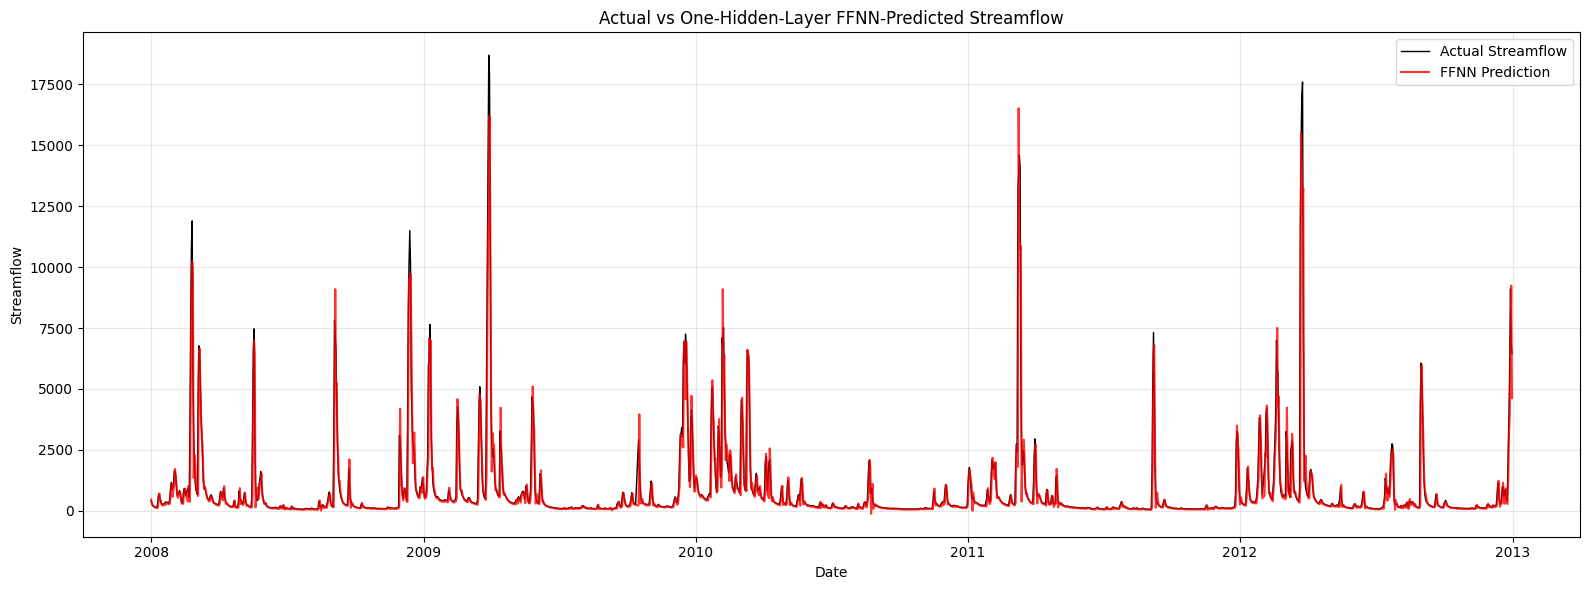

In [37]:
# Plot actual versus FFNN-predicted streamflow

plt.figure(figsize=(16, 6))

plt.plot(
    dates_validation,
    actual_streamflow,
    label="Actual Streamflow",
    color="black",
    linewidth=1
)

plt.plot(
    dates_validation,
    ffnn_predictions,
    label="FFNN Prediction",
    color="red",
    alpha=0.8
)

plt.title(
    "Actual vs One-Hidden-Layer FFNN-Predicted Streamflow"
)
plt.xlabel("Date")
plt.ylabel("Streamflow")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


#  74 — Plot the LSTM Predictions

This plot compares actual validation streamflow with the predictions from the one-hidden-layer LSTM.


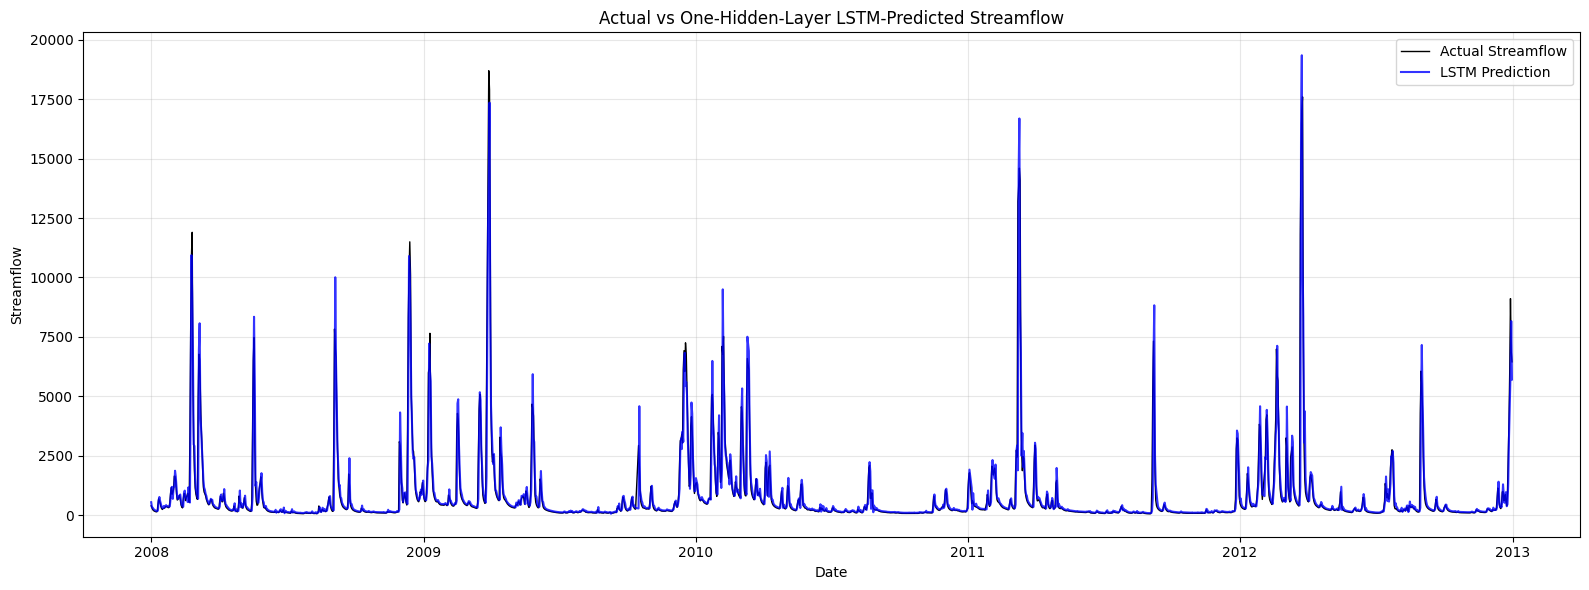

In [38]:
# Plot actual versus LSTM-predicted streamflow

plt.figure(figsize=(16, 6))

plt.plot(
    dates_lstm_validation,
    actual_lstm_streamflow,
    label="Actual Streamflow",
    color="black",
    linewidth=1
)

plt.plot(
    dates_lstm_validation,
    lstm_predictions,
    label="LSTM Prediction",
    color="blue",
    alpha=0.8
)

plt.title(
    "Actual vs One-Hidden-Layer LSTM-Predicted Streamflow"
)
plt.xlabel("Date")
plt.ylabel("Streamflow")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


# 76 — Compare the Single-Hidden-Layer Models
The single-hidden-layer FFNN and single-hidden-layer LSTM are evaluated and compared using Validation RMSE.


In [39]:
# Compare the models using RMSE

if ffnn_metrics["RMSE"] < lstm_metrics["RMSE"]:
    better_model = "FFNN"
else:
    better_model = "LSTM"

print(
    "hidden-layer FFNN validation RMSE:",
    round(ffnn_metrics["RMSE"], 4)
)

print(
    "hidden-layer LSTM validation RMSE:",
    round(lstm_metrics["RMSE"], 4)
)

print(
    "\nBetter model according to validation RMSE:",
    better_model
)


hidden-layer FFNN validation RMSE: 727.9262
hidden-layer LSTM validation RMSE: 689.0007

Better model according to validation RMSE: LSTM


#  78 — Display the Final Baseline Summary

This table displays the main validation results of the two baseline models.

The final comparison is based mainly on validation RMSE.


In [40]:
# Display the main baseline comparison

baseline_summary = comparison_table[
    [
        "Model",
        "Validation_RMSE",

        "Peak_RMSE",
        "NonPeak_RMSE"
    ]
].copy()

display(
    baseline_summary.round(4)
)


,Model,Validation_RMSE,Peak_RMSE,NonPeak_RMSE
0,Tuned FFNN,727.9262,2047.0048,155.5651
1,LSTM,689.0007,1924.6994,168.9203


#  80 — Compare Training and Validation using RMSE

This cell calculates and displays RMSE for both the training and validation datasets.

The comparison includes:

- FFNN training RMSE
- FFNN validation RMSE
- LSTM training RMSE
- LSTM validation RMSE


In [41]:
# Calculate training RMSE for both models

ffnn_training_predictions_scaled = ffnn_model.predict(
    X_train_scaled,
    verbose=0
)

ffnn_training_predictions = (
    target_scaler.inverse_transform(
        ffnn_training_predictions_scaled
    )
    .flatten()
)

actual_ffnn_training_streamflow = (
    y_train.to_numpy().flatten()
)


lstm_training_predictions_scaled = lstm_model.predict(
    X_lstm_train,
    verbose=0
)

lstm_training_predictions = (
    lstm_target_scaler.inverse_transform(
        lstm_training_predictions_scaled
    )
    .flatten()
)

actual_lstm_training_streamflow = (
    lstm_target_scaler.inverse_transform(
        y_lstm_train.reshape(-1, 1)
    )
    .flatten()
)


# Calculate training RMSE

ffnn_training_metrics = calculate_metrics(
    actual_ffnn_training_streamflow,
    ffnn_training_predictions
)

lstm_training_metrics = calculate_metrics(
    actual_lstm_training_streamflow,
    lstm_training_predictions
)


# Create the training and validation RMSE table

training_validation_comparison = pd.DataFrame([
    {
        "Model": "Tuned FFNN",
        "Training_RMSE": ffnn_training_metrics["RMSE"],
        "Validation_RMSE": ffnn_metrics["RMSE"]
    },
    {
        "Model": "LSTM",
        "Training_RMSE": lstm_training_metrics["RMSE"],
        "Validation_RMSE": lstm_metrics["RMSE"]
    }
])

display(
    training_validation_comparison.round(4)
)


,Model,Training_RMSE,Validation_RMSE
0,Tuned FFNN,770.9010,727.9262
1,LSTM,631.8263,689.0007


#  82 — Calculate RMSE Relative to Maximum Streamflow

This cell calculates RMSE as a percentage of the maximum actual streamflow.

\[
\text{RMSE relative to max flow (\%)}=
\frac{\text{RMSE}}{\text{Maximum streamflow}}\times100
\]

The calculation is performed for:

- FFNN training data
- FFNN validation data
- LSTM training data
- LSTM validation data

A lower percentage indicates a smaller error relative to the maximum streamflow.


In [42]:
def calculate_relative_rmse_percent(
    actual,
    predicted
):
    actual = np.asarray(
        actual,
        dtype=float
    )

    predicted = np.asarray(
        predicted,
        dtype=float
    )

    rmse = np.sqrt(
        mean_squared_error(
            actual,
            predicted
        )
    )

    maximum_streamflow = np.max(
        actual
    )

    relative_rmse_percent = (
        rmse
        / maximum_streamflow
        * 100
    )

    return {
        "RMSE": rmse,
        "RMSE_relative_to_max_flow_percent": (
            relative_rmse_percent
        ),
        "Maximum_Streamflow": maximum_streamflow
    }


ffnn_training_relative_metrics = (
    calculate_relative_rmse_percent(
        actual_ffnn_training_streamflow,
        ffnn_training_predictions
    )
)

ffnn_validation_relative_metrics = (
    calculate_relative_rmse_percent(
        actual_streamflow,
        ffnn_predictions
    )
)

lstm_training_relative_metrics = (
    calculate_relative_rmse_percent(
        actual_lstm_training_streamflow,
        lstm_training_predictions
    )
)

lstm_validation_relative_metrics = (
    calculate_relative_rmse_percent(
        actual_lstm_streamflow,
        lstm_predictions
    )
)


relative_rmse_table = pd.DataFrame([
    {
        "Model": "Tuned FFNN",
        "Dataset": "Training",
        "RMSE": ffnn_training_relative_metrics[
            "RMSE"
        ],
        "Maximum_Streamflow": (
            ffnn_training_relative_metrics[
                "Maximum_Streamflow"
            ]
        ),
        "RMSE_relative_to_max_flow_percent": (
            ffnn_training_relative_metrics[
                "RMSE_relative_to_max_flow_percent"
            ]
        )
    },
    {
        "Model": "Tuned FFNN",
        "Dataset": "Validation",
        "RMSE": ffnn_validation_relative_metrics[
            "RMSE"
        ],
        "Maximum_Streamflow": (
            ffnn_validation_relative_metrics[
                "Maximum_Streamflow"
            ]
        ),
        "RMSE_relative_to_max_flow_percent": (
            ffnn_validation_relative_metrics[
                "RMSE_relative_to_max_flow_percent"
            ]
        )
    },
    {
        "Model": "LSTM",
        "Dataset": "Training",
        "RMSE": lstm_training_relative_metrics[
            "RMSE"
        ],
        "Maximum_Streamflow": (
            lstm_training_relative_metrics[
                "Maximum_Streamflow"
            ]
        ),
        "RMSE_relative_to_max_flow_percent": (
            lstm_training_relative_metrics[
                "RMSE_relative_to_max_flow_percent"
            ]
        )
    },
    {
        "Model": "LSTM",
        "Dataset": "Validation",
        "RMSE": lstm_validation_relative_metrics[
            "RMSE"
        ],
        "Maximum_Streamflow": (
            lstm_validation_relative_metrics[
                "Maximum_Streamflow"
            ]
        ),
        "RMSE_relative_to_max_flow_percent": (
            lstm_validation_relative_metrics[
                "RMSE_relative_to_max_flow_percent"
            ]
        )
    }
])

print("RMSE")

display(
    relative_rmse_table.round(4)
)

RMSE


,Model,Dataset,RMSE,Maximum_Streamflow,RMSE_relative_to_max_flow_percent
0,Tuned FFNN,Training,770.9010,29700.0,2.5956
1,Tuned FFNN,Validation,727.9262,18700.0,3.8927
2,LSTM,Training,631.8263,29700.0,2.1274
3,LSTM,Validation,689.0007,18700.0,3.6845
